# NEAT - NeuroEvolution of Augmenting Topologies

Ce notebook permet d'interagir avec l'implémentation NEAT et de tester les différentes classes.

## 1. Import des modules

In [1]:
import matplotlib.pyplot as plt

from neat_classes import *
from neat_evolution import *


## 2. Test de la classe Node

In [2]:
# Créer différents types de noeuds
sensor_node = Node(node_type=NodeType.SENSOR, layer=0.0)
hidden_node = Node(node_type=NodeType.HIDDEN, activation=ActivationFunction.TANH, bias=0.5, layer=0.5)
output_node = Node(node_type=NodeType.OUTPUT, activation=ActivationFunction.SIGMOID, layer=1.0)

print("=" * 60)
print("NOEUDS CRÉÉS")
print("=" * 60)
print(f"1. {sensor_node}")
print(f"2. {hidden_node}")
print(f"3. {output_node}")

# Tester toutes les fonctions d'activation
print("\n" + "=" * 60)
print("TEST DES FONCTIONS D'ACTIVATION")
print("=" * 60)

test_values = [-2.0, -1.0, 0.0, 0.5, 1.0, 2.0]
activations = [
    (ActivationFunction.SIGMOID, "Sigmoid"),
    (ActivationFunction.TANH, "Tanh"),
    (ActivationFunction.RELU, "ReLU"),
    (ActivationFunction.LINEAR, "Linear")
]

for activation_func, name in activations:
    test_node = Node(node_type=NodeType.HIDDEN, activation=activation_func, layer=0.5)
    print(f"\n{name}:")
    results = [test_node.activate(val) for val in test_values]
    print(f"  Input:  {test_values}")
    print(f"  Output: {[f'{r:.4f}' for r in results]}")

NOEUDS CRÉÉS
1. Node(type=sensor, activation=relu, bias=0.00, layer=0.00, value=0.00)
2. Node(type=hidden, activation=tanh, bias=0.50, layer=0.50, value=0.00)
3. Node(type=output, activation=sigmoid, bias=0.00, layer=1.00, value=0.00)

TEST DES FONCTIONS D'ACTIVATION

Sigmoid:
  Input:  [-2.0, -1.0, 0.0, 0.5, 1.0, 2.0]
  Output: ['0.1192', '0.2689', '0.5000', '0.6225', '0.7311', '0.8808']

Tanh:
  Input:  [-2.0, -1.0, 0.0, 0.5, 1.0, 2.0]
  Output: ['-0.9640', '-0.7616', '0.0000', '0.4621', '0.7616', '0.9640']

ReLU:
  Input:  [-2.0, -1.0, 0.0, 0.5, 1.0, 2.0]
  Output: ['0.0000', '0.0000', '0.0000', '0.5000', '1.0000', '2.0000']

Linear:
  Input:  [-2.0, -1.0, 0.0, 0.5, 1.0, 2.0]
  Output: ['-2.0000', '-1.0000', '0.0000', '0.5000', '1.0000', '2.0000']


## 3. Test de la classe Connection

In [3]:
# Créer des connexions
conn1 = Connection(innovation=0, input_node_idx=0, output_node_idx=2, weight=0.75)
conn2 = Connection(innovation=1, input_node_idx=1, output_node_idx=2, weight=-0.5, enabled=True)
conn3 = Connection(innovation=2, input_node_idx=0, output_node_idx=1, weight=1.2, enabled=False)

print("Connexions créées:")
print(conn1)
print(conn2)
print(conn3)

# Copier une connexion
conn_copy = conn1.copy()
print(f"\nCopie de connexion: {conn_copy}")

Connexions créées:
Connection(innov=0, 0->2, w=0.750, enabled)
Connection(innov=1, 1->2, w=-0.500, enabled)
Connection(innov=2, 0->1, w=1.200, disabled)

Copie de connexion: Connection(innov=0, 0->2, w=0.750, enabled)


## 4. Test de la classe Genome

GÉNOME SIMPLE CRÉÉ
╔═══════════════════════════════════════════════╗
║ Genome ID: 1                                  ║
║ Fitness:   0.000000                           ║
╠═══════════════════════════════════════════════╣
║ STRUCTURE                                     ║
║   Inputs:  2                                  ║
║   Hidden:  0                                  ║
║   Outputs: 1                                  ║
║   Total:   3                                  ║
╠═══════════════════════════════════════════════╣
║ CONNECTIONS                                   ║
║   Active:   2                                 ║
║   Disabled: 0                                 ║
║   Total:    2                                 ║
╚═══════════════════════════════════════════════╝

Nombre d'inputs: 2
Nombre d'outputs: 1

Noeuds:
  [0] Node(type=sensor, activation=linear, bias=0.00, layer=0.00, value=0.00)
  [1] Node(type=sensor, activation=linear, bias=0.00, layer=0.00, value=0.00)
  [2] Node(type=output, ac

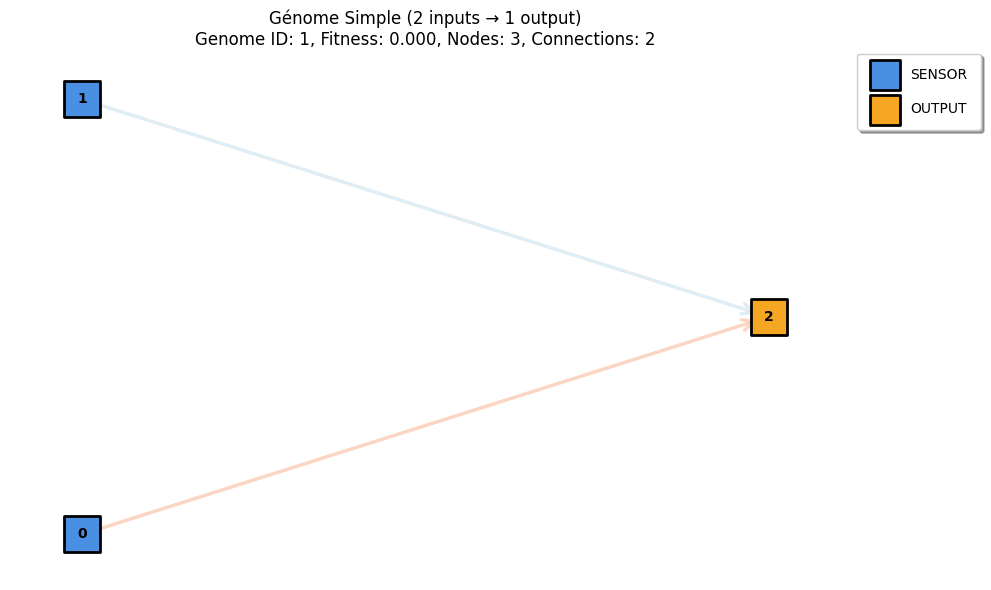

In [4]:
# Créer un génome simple manuellement
genome = Genome(genome_id=1)

# Ajouter des noeuds
genome.add_node(Node(node_type=NodeType.SENSOR, activation=ActivationFunction.LINEAR, layer=0.0))
genome.add_node(Node(node_type=NodeType.SENSOR, activation=ActivationFunction.LINEAR, layer=0.0))
genome.add_node(Node(node_type=NodeType.OUTPUT, activation=ActivationFunction.SIGMOID, layer=1.0))

# Ajouter des connexions
genome.add_connection(Connection(innovation=0, input_node_idx=0, output_node_idx=2, weight=0.5))
genome.add_connection(Connection(innovation=1, input_node_idx=1, output_node_idx=2, weight=-0.3))

print("=" * 60)
print("GÉNOME SIMPLE CRÉÉ")
print("=" * 60)
print(genome)
print(f"\nNombre d'inputs: {genome.num_inputs}")
print(f"Nombre d'outputs: {genome.num_outputs}")
print(f"\nNoeuds:")
for i, node in enumerate(genome.nodes):
    print(f"  [{i}] {node}")
print(f"\nConnexions:")
for conn in genome.connections:
    print(f"  {conn}")

# Visualiser le génome simple
visualize_genome(genome, title="Génome Simple (2 inputs → 1 output)", figsize=(10, 6))

## 5. Test de la fonction forward_pass

In [5]:
# Tester la propagation avant
print("=" * 60)
print("TEST FORWARD PASS")
print("=" * 60)

test_cases = [
    [1.0, 0.0],
    [0.0, 1.0],
    [1.0, 1.0],
    [0.5, 0.5],
    [-1.0, 1.0]
]

for inputs in test_cases:
    outputs = genome.forward_pass(inputs)
    print(f"\nEntrées: {inputs}")
    print(f"Sorties: {[f'{o:.4f}' for o in outputs]}")
    print(f"Calcul détaillé: sigmoid({inputs[0]}*0.5 + {inputs[1]}*(-0.3)) = {outputs[0]:.4f}")

TEST FORWARD PASS

Entrées: [1.0, 0.0]
Sorties: ['0.6225']
Calcul détaillé: sigmoid(1.0*0.5 + 0.0*(-0.3)) = 0.6225

Entrées: [0.0, 1.0]
Sorties: ['0.4256']
Calcul détaillé: sigmoid(0.0*0.5 + 1.0*(-0.3)) = 0.4256

Entrées: [1.0, 1.0]
Sorties: ['0.5498']
Calcul détaillé: sigmoid(1.0*0.5 + 1.0*(-0.3)) = 0.5498

Entrées: [0.5, 0.5]
Sorties: ['0.5250']
Calcul détaillé: sigmoid(0.5*0.5 + 0.5*(-0.3)) = 0.5250

Entrées: [-1.0, 1.0]
Sorties: ['0.3100']
Calcul détaillé: sigmoid(-1.0*0.5 + 1.0*(-0.3)) = 0.3100


## 6. Création d'un génome initial fully connected

GÉNOME INITIAL FULLY CONNECTED
╔═══════════════════════════════════════════════╗
║ Genome ID: 100                                ║
║ Fitness:   0.000000                           ║
╠═══════════════════════════════════════════════╣
║ STRUCTURE                                     ║
║   Inputs:  3                                  ║
║   Hidden:  0                                  ║
║   Outputs: 2                                  ║
║   Total:   5                                  ║
╠═══════════════════════════════════════════════╣
║ CONNECTIONS                                   ║
║   Active:   6                                 ║
║   Disabled: 0                                 ║
║   Total:    6                                 ║
╚═══════════════════════════════════════════════╝

Structure: 3 inputs → 2 outputs
Nombre total de connexions: 6

CONNEXIONS
1. Connection(innov=1, 0->3, w=1.239, enabled)
2. Connection(innov=2, 0->4, w=0.024, enabled)
3. Connection(innov=3, 1->3, w=1.065, enabled)
4. 

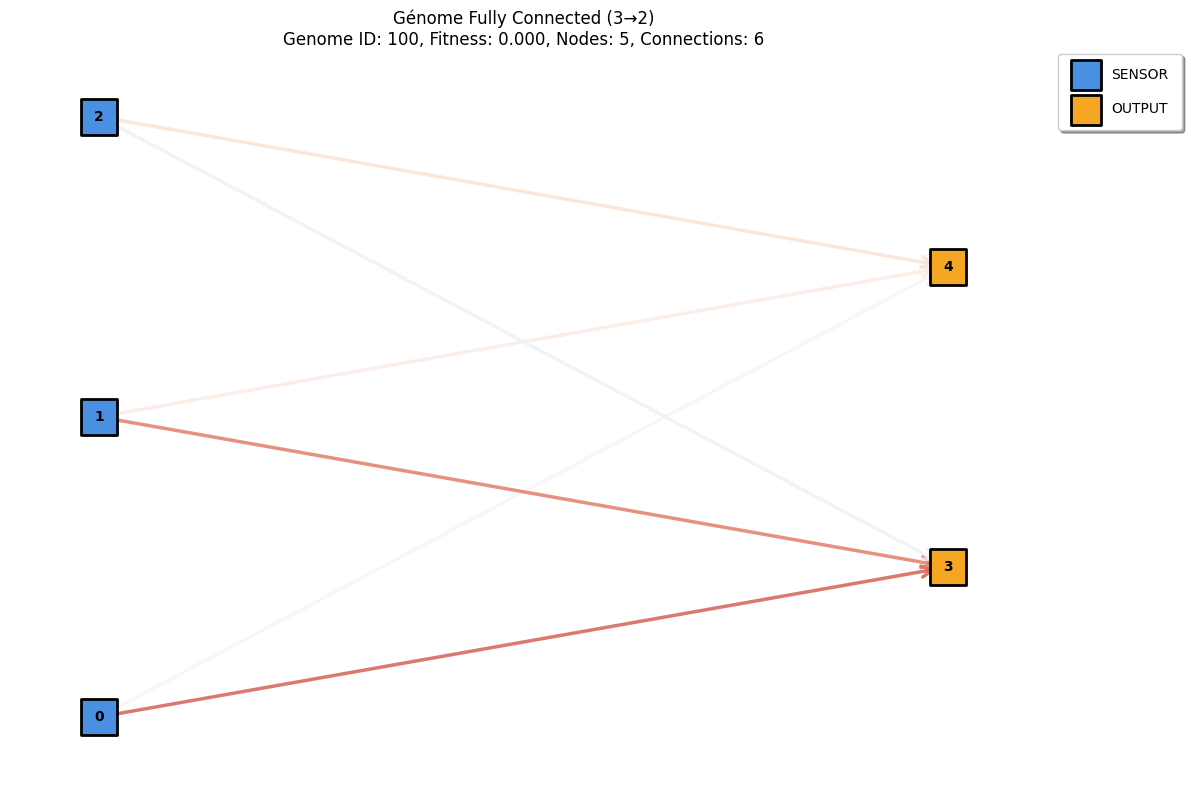

In [6]:
# Créer un génome initial avec 3 entrées et 2 sorties
initial_genome = create_initial_genome(
    genome_id=100,
    num_inputs=3,
    num_outputs=2,
    fully_connected=True
)

print("=" * 60)
print("GÉNOME INITIAL FULLY CONNECTED")
print("=" * 60)
print(initial_genome)
print(f"\nStructure: {initial_genome.num_inputs} inputs → {initial_genome.num_outputs} outputs")
print(f"Nombre total de connexions: {len(initial_genome.connections)}")

print("\n" + "=" * 60)
print("CONNEXIONS")
print("=" * 60)
for i, conn in enumerate(initial_genome.connections):
    print(f"{i+1}. {conn}")
    
# Visualiser le réseau fully connected
visualize_genome(initial_genome, title="Génome Fully Connected (3→2)", figsize=(12, 8))

## 7. Tests de propagation avec différentes entrées

In [7]:
# Tester le génome avec différentes entrées
test_inputs = [
    [1.0, 0.0, 0.0],
    [0.0, 1.0, 0.0],
    [0.0, 0.0, 1.0],
    [1.0, 1.0, 1.0],
    [0.5, 0.5, 0.5],
    [-1.0, 0.0, 1.0]
]

print("=" * 70)
print("TESTS DE PROPAGATION FORWARD")
print("=" * 70)
print(f"{'Entrées':<30} | {'Output 1':>10} | {'Output 2':>10}")
print("-" * 70)

for inputs in test_inputs:
    outputs = initial_genome.forward_pass(inputs)
    inputs_str = f"[{inputs[0]:>5.1f}, {inputs[1]:>5.1f}, {inputs[2]:>5.1f}]"
    print(f"{inputs_str:<30} | {outputs[0]:>10.4f} | {outputs[1]:>10.4f}")

print("=" * 70)

TESTS DE PROPAGATION FORWARD
Entrées                        |   Output 1 |   Output 2
----------------------------------------------------------------------
[  1.0,   0.0,   0.0]          |     0.7753 |     0.5060
[  0.0,   1.0,   0.0]          |     0.7436 |     0.5407
[  0.0,   0.0,   1.0]          |     0.4746 |     0.5779
[  1.0,   1.0,   1.0]          |     0.9004 |     0.6228
[  0.5,   0.5,   0.5]          |     0.7504 |     0.5623
[ -1.0,   0.0,   1.0]          |     0.2075 |     0.5721


## 8. Test avec un génome contenant un noeud caché

GÉNOME AVEC NOEUD CACHÉ
╔═══════════════════════════════════════════════╗
║ Genome ID: 200                                ║
║ Fitness:   0.000000                           ║
╠═══════════════════════════════════════════════╣
║ STRUCTURE                                     ║
║   Inputs:  2                                  ║
║   Hidden:  1                                  ║
║   Outputs: 1                                  ║
║   Total:   4                                  ║
╠═══════════════════════════════════════════════╣
║ CONNECTIONS                                   ║
║   Active:   3                                 ║
║   Disabled: 1                                 ║
║   Total:    4                                 ║
╚═══════════════════════════════════════════════╝

Architecture: 2 → 1 hidden → 1
Connexions actives: 3/4


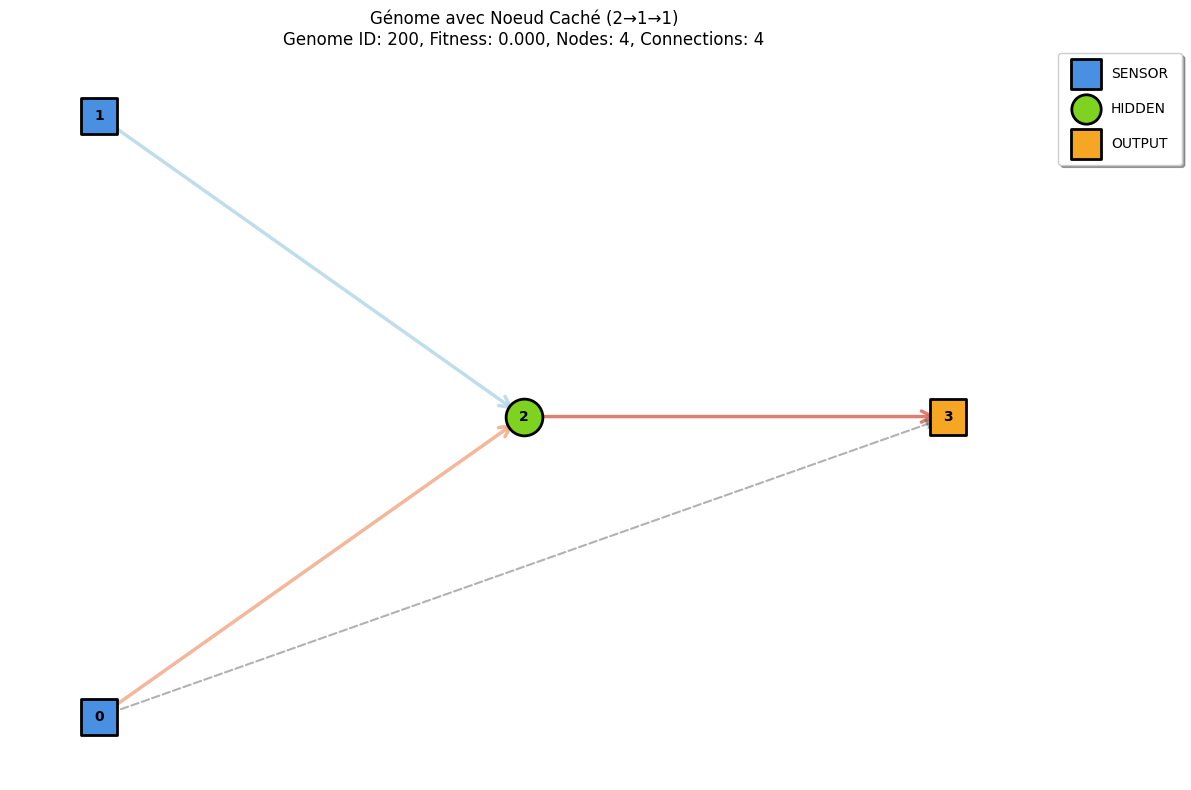

In [8]:
# Créer un génome avec un noeud caché
complex_genome = Genome(genome_id=200)

# Ajouter 2 sensors
complex_genome.add_node(Node(node_type=NodeType.SENSOR, activation=ActivationFunction.LINEAR, layer=0.0))
complex_genome.add_node(Node(node_type=NodeType.SENSOR, activation=ActivationFunction.LINEAR, layer=0.0))

# Ajouter 1 hidden
complex_genome.add_node(Node(node_type=NodeType.HIDDEN, activation=ActivationFunction.TANH, bias=0.5, layer=0.5))

# Ajouter 1 output
complex_genome.add_node(Node(node_type=NodeType.OUTPUT, activation=ActivationFunction.SIGMOID, layer=1.0))

# Connexions: sensor → hidden → output
complex_genome.add_connection(Connection(innovation=0, input_node_idx=0, output_node_idx=2, weight=0.8))
complex_genome.add_connection(Connection(innovation=1, input_node_idx=1, output_node_idx=2, weight=-0.6))
complex_genome.add_connection(Connection(innovation=2, input_node_idx=2, output_node_idx=3, weight=1.2))

# Connexion directe désactivée
complex_genome.add_connection(Connection(innovation=3, input_node_idx=0, output_node_idx=3, weight=0.3, enabled=False))

print("=" * 60)
print("GÉNOME AVEC NOEUD CACHÉ")
print("=" * 60)
print(complex_genome)
print(f"\nArchitecture: {complex_genome.num_inputs} → 1 hidden → {complex_genome.num_outputs}")
print(f"Connexions actives: {sum(1 for c in complex_genome.connections if c.enabled)}/{len(complex_genome.connections)}")

# Visualiser le génome avec noeud caché
visualize_genome(complex_genome, title="Génome avec Noeud Caché (2→1→1)", figsize=(12, 8))

## 9. Test des mutations - Configuration

In [9]:
# Créer une configuration de mutation par défaut
config = MutationConfig(
    prob_add_connection=0,    
    prob_add_node=0 )

print("=" * 60)
print("CONFIGURATION DES MUTATIONS")
print("=" * 60)
print(config)

CONFIGURATION DES MUTATIONS
MutationConfig(prob_mutate_activation=0.1, prob_mutate_bias=0.3, bias_mutation_power=0.2, bias_replace_rate=0.01, prob_mutate_weight=0.8, weight_mutation_power=0.5, weight_replace_rate=0.01, prob_toggle_connection=0.01, prob_add_connection=0, prob_add_node=0, bias_min=-2.0, bias_max=2.0, weight_min=-5.0, weight_max=5.0)


## 10. Test de mutation d'un noeud

In [10]:
# Tester la mutation d'un noeud
test_node = Node(node_type=NodeType.HIDDEN, activation=ActivationFunction.SIGMOID, bias=0.5, layer=0.5)

print("=" * 60)
print("TEST DE MUTATION D'UN NOEUD")
print("=" * 60)
print(f"\nAVANT mutation:")
print(f"  {test_node}")

# Appliquer plusieurs mutations pour voir les effets
print(f"\nApplication de 10 mutations...")
mutation_config = MutationConfig(
    prob_mutate_activation=0.3,  # 30% de chance
    prob_mutate_bias=0.8          # 80% de chance
)

for i in range(10):
    old_activation = test_node.activation
    old_bias = test_node.bias
    
    test_node.mutate(mutation_config)
    
    if old_activation != test_node.activation or abs(old_bias - test_node.bias) > 0.001:
        print(f"\n  Mutation #{i+1}:")
        if old_activation != test_node.activation:
            print(f"    Activation: {old_activation.value} → {test_node.activation.value}")
        if abs(old_bias - test_node.bias) > 0.001:
            print(f"    Biais: {old_bias:.4f} → {test_node.bias:.4f}")

print(f"\nAPRÈS mutations:")
print(f"  {test_node}")
print("=" * 60)

TEST DE MUTATION D'UN NOEUD

AVANT mutation:
  Node(type=hidden, activation=sigmoid, bias=0.50, layer=0.50, value=0.00)

Application de 10 mutations...

  Mutation #1:
    Biais: 0.5000 → 0.6079

  Mutation #4:
    Biais: 0.6079 → 0.5454

  Mutation #6:
    Biais: 0.5454 → 0.3543

  Mutation #7:
    Biais: 0.3543 → 0.3422

  Mutation #9:
    Biais: 0.3422 → 0.1979

  Mutation #10:
    Activation: sigmoid → tanh
    Biais: 0.1979 → 0.4327

APRÈS mutations:
  Node(type=hidden, activation=tanh, bias=0.43, layer=0.50, value=0.00)


## 11. Test de mutation d'une connexion

In [11]:
# Tester la mutation d'une connexion
test_conn = Connection(innovation=99, input_node_idx=0, output_node_idx=1, weight=1.5, enabled=True)

print("=" * 60)
print("TEST DE MUTATION D'UNE CONNEXION")
print("=" * 60)
print(f"\nAVANT mutation:")
print(f"  {test_conn}")

# Appliquer plusieurs mutations
mutation_config = MutationConfig(
    prob_mutate_weight=1.0,        # 100% de chance de muter le poids
    prob_toggle_connection=0.1     # 10% de chance de toggle
)

print(f"\nApplication de 15 mutations...")
for i in range(15):
    old_weight = test_conn.weight
    old_enabled = test_conn.enabled
    
    test_conn.mutate(mutation_config)
    
    if abs(old_weight - test_conn.weight) > 0.001 or old_enabled != test_conn.enabled:
        print(f"\n  Mutation #{i+1}:")
        if abs(old_weight - test_conn.weight) > 0.001:
            print(f"    Poids: {old_weight:.4f} → {test_conn.weight:.4f} (Δ = {test_conn.weight - old_weight:.4f})")
        if old_enabled != test_conn.enabled:
            print(f"    État: {'enabled' if old_enabled else 'disabled'} → {'enabled' if test_conn.enabled else 'disabled'}")

print(f"\nAPRÈS mutations:")
print(f"  {test_conn}")
print("=" * 60)

TEST DE MUTATION D'UNE CONNEXION

AVANT mutation:
  Connection(innov=99, 0->1, w=1.500, enabled)

Application de 15 mutations...

  Mutation #1:
    Poids: 1.5000 → 0.5775 (Δ = -0.9225)

  Mutation #2:
    Poids: 0.5775 → 0.1461 (Δ = -0.4314)

  Mutation #3:
    Poids: 0.1461 → 0.0811 (Δ = -0.0650)

  Mutation #4:
    Poids: 0.0811 → 0.9657 (Δ = 0.8847)
    État: enabled → disabled

  Mutation #5:
    Poids: 0.9657 → 1.4905 (Δ = 0.5248)

  Mutation #6:
    Poids: 1.4905 → 1.2152 (Δ = -0.2753)

  Mutation #7:
    Poids: 1.2152 → 0.7921 (Δ = -0.4232)

  Mutation #8:
    Poids: 0.7921 → 0.8759 (Δ = 0.0838)

  Mutation #9:
    Poids: 0.8759 → 1.0512 (Δ = 0.1753)

  Mutation #10:
    Poids: 1.0512 → 0.9279 (Δ = -0.1233)

  Mutation #11:
    Poids: 0.9279 → 0.6703 (Δ = -0.2576)

  Mutation #12:
    Poids: 0.6703 → 0.7851 (Δ = 0.1148)
    État: disabled → enabled

  Mutation #13:
    Poids: 0.7851 → 0.8011 (Δ = 0.0160)
    État: enabled → disabled

  Mutation #14:
    Poids: 0.8011 → 0.3933 (

## 12. Test de mutation d'un génome complet

In [12]:
# Créer un génome et le muter
mutation_test_genome = create_initial_genome(500, num_inputs=2, num_outputs=1, fully_connected=True)

print("=" * 60)
print("MUTATION D'UN GÉNOME COMPLET")
print("=" * 60)

# Afficher l'état initial
print("\nGénome AVANT mutation:")
print(mutation_test_genome)
print("\nNoeuds:")
for i, node in enumerate(mutation_test_genome.nodes):
    print(f"  [{i}] {node}")
print("\nConnexions:")
for conn in mutation_test_genome.connections:
    print(f"  {conn}")

# Faire une copie pour comparer
original_genome = mutation_test_genome.copy()

# Configurer les mutations (plus agressives pour voir les effets)
mutation_config = MutationConfig(
    prob_mutate_activation=0.5,
    prob_mutate_bias=0.8,
    prob_mutate_weight=1.0,
    weight_mutation_power=0.8,
    prob_toggle_connection=0.1
)

# Appliquer la mutation
mutation_test_genome.mutate(mutation_config)

print("\n" + "=" * 60)
print("Génome APRÈS mutation:")
print(mutation_test_genome)
print("\nNoeuds:")
for i, node in enumerate(mutation_test_genome.nodes):
    print(f"  [{i}] {node}")
print("\nConnexions:")
for conn in mutation_test_genome.connections:
    print(f"  {conn}")

# Comparer les changements
print("\n" + "=" * 60)
print("ANALYSE DES CHANGEMENTS")
print("=" * 60)

activation_changes = sum(1 for i in range(len(original_genome.nodes)) 
                        if original_genome.nodes[i].activation != mutation_test_genome.nodes[i].activation)
bias_changes = sum(1 for i in range(len(original_genome.nodes)) 
                  if abs(original_genome.nodes[i].bias - mutation_test_genome.nodes[i].bias) > 0.001)
weight_changes = sum(1 for i in range(len(original_genome.connections)) 
                    if abs(original_genome.connections[i].weight - mutation_test_genome.connections[i].weight) > 0.001)
toggle_changes = sum(1 for i in range(len(original_genome.connections)) 
                    if original_genome.connections[i].enabled != mutation_test_genome.connections[i].enabled)

print(f"\nChangements dans les noeuds:")
print(f"  Fonctions d'activation changées: {activation_changes}/{len(mutation_test_genome.nodes)}")
print(f"  Biais modifiés: {bias_changes}/{len(mutation_test_genome.nodes)}")
print(f"\nChangements dans les connexions:")
print(f"  Poids modifiés: {weight_changes}/{len(mutation_test_genome.connections)}")
print(f"  Connexions toggles: {toggle_changes}/{len(mutation_test_genome.connections)}")
print("=" * 60)

MUTATION D'UN GÉNOME COMPLET

Génome AVANT mutation:
╔═══════════════════════════════════════════════╗
║ Genome ID: 500                                ║
║ Fitness:   0.000000                           ║
╠═══════════════════════════════════════════════╣
║ STRUCTURE                                     ║
║   Inputs:  2                                  ║
║   Hidden:  0                                  ║
║   Outputs: 1                                  ║
║   Total:   3                                  ║
╠═══════════════════════════════════════════════╣
║ CONNECTIONS                                   ║
║   Active:   2                                 ║
║   Disabled: 0                                 ║
║   Total:    2                                 ║
╚═══════════════════════════════════════════════╝

Noeuds:
  [0] Node(type=sensor, activation=linear, bias=0.00, layer=0.00, value=0.00)
  [1] Node(type=sensor, activation=linear, bias=0.00, layer=0.00, value=0.00)
  [2] Node(type=output, activati

## 13. Visualisation : Avant et Après mutation

Génome ORIGINAL:


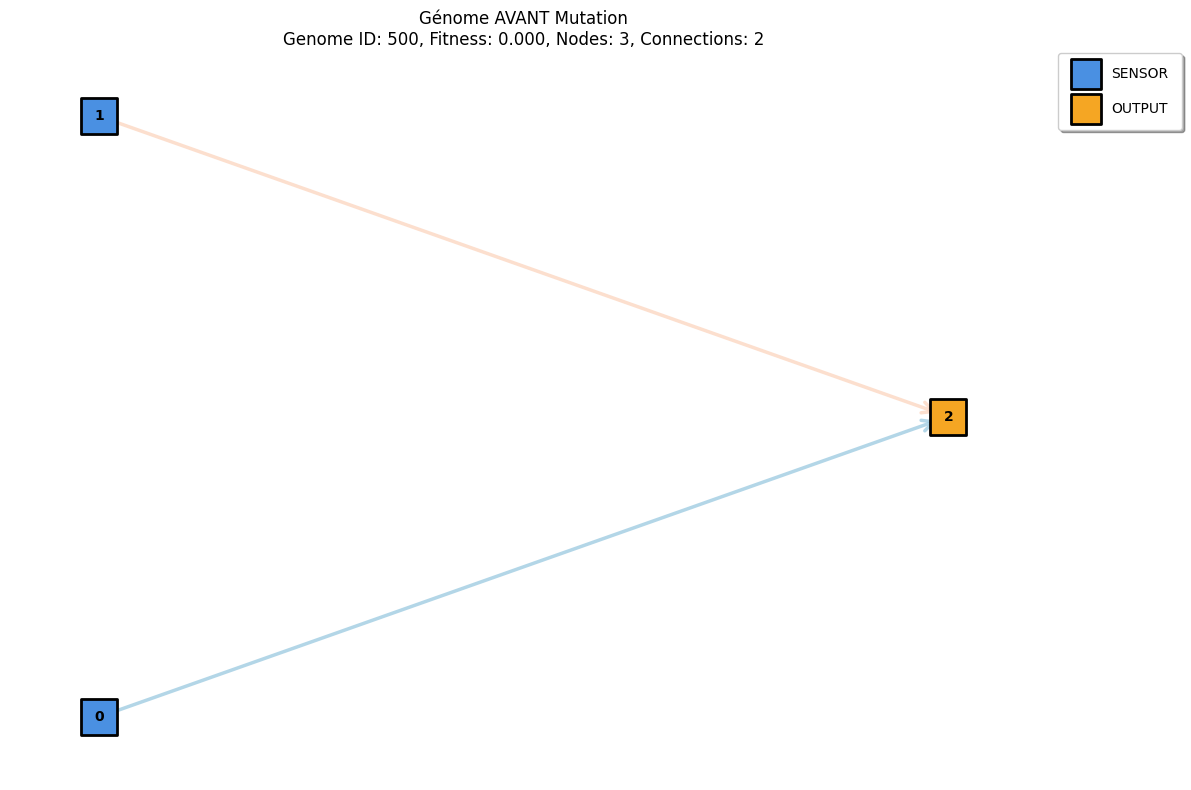


Génome MUTÉ:


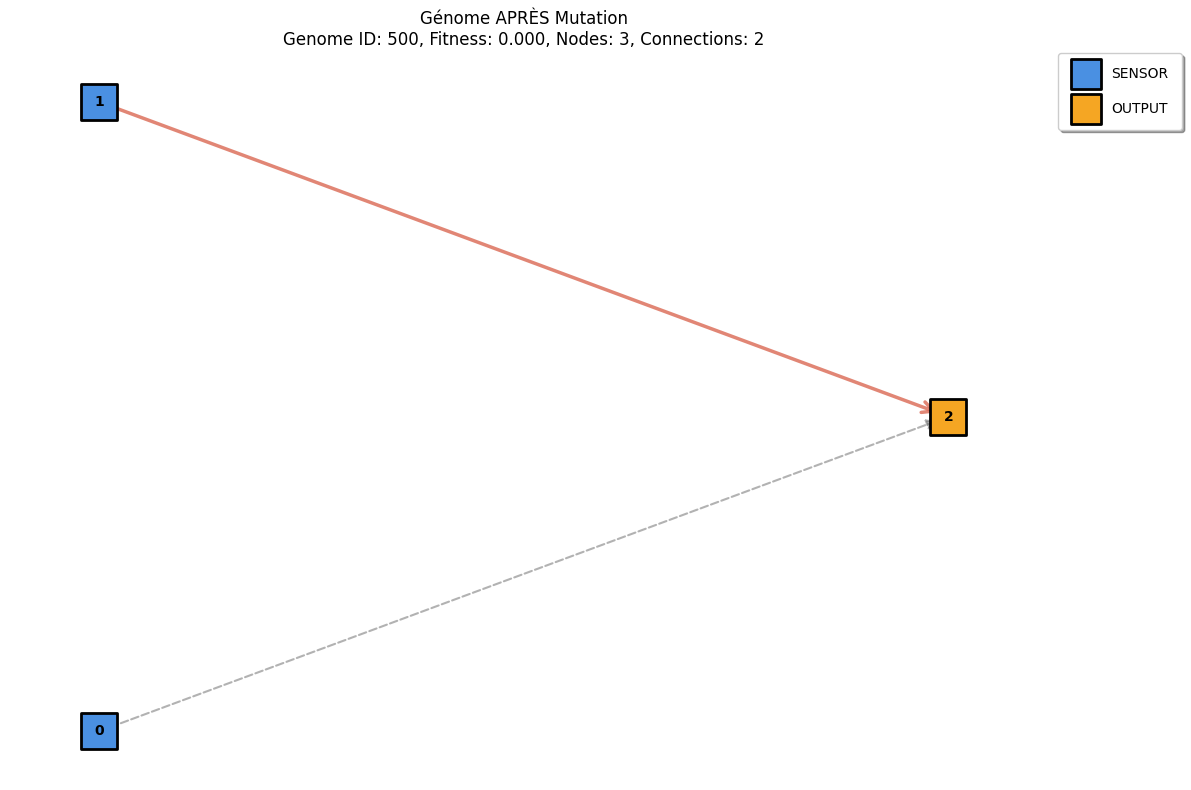

In [13]:
# Visualiser l'original et le muté
print("Génome ORIGINAL:")
visualize_genome(original_genome, title="Génome AVANT Mutation", figsize=(12, 8))

print("\nGénome MUTÉ:")
visualize_genome(mutation_test_genome, title="Génome APRÈS Mutation", figsize=(12, 8))

## 14. Test ADD_CONNECTION - Ajouter une connexion

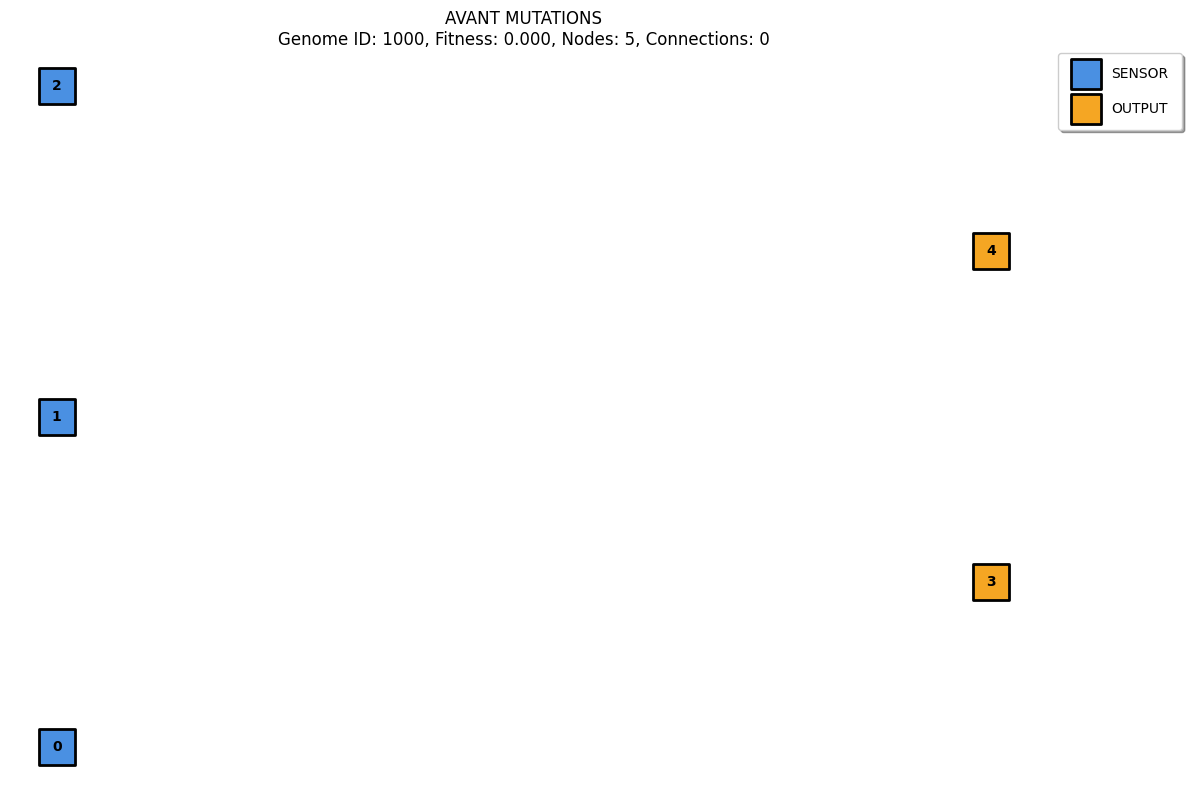

TEST ADD_CONNECTION

AVANT mutation:
╔═══════════════════════════════════════════════╗
║ Genome ID: 1000                               ║
║ Fitness:   0.000000                           ║
╠═══════════════════════════════════════════════╣
║ STRUCTURE                                     ║
║   Inputs:  3                                  ║
║   Hidden:  0                                  ║
║   Outputs: 2                                  ║
║   Total:   5                                  ║
╠═══════════════════════════════════════════════╣
║ CONNECTIONS                                   ║
║   Active:   0                                 ║
║   Disabled: 0                                 ║
║   Total:    0                                 ║
╚═══════════════════════════════════════════════╝
Connexions: 0
Aucune connexion initiale

Numéro d'innovation avant: 8

----------------------------------------------------------------------
Ajout de 5 connexions...
----------------------------------------------

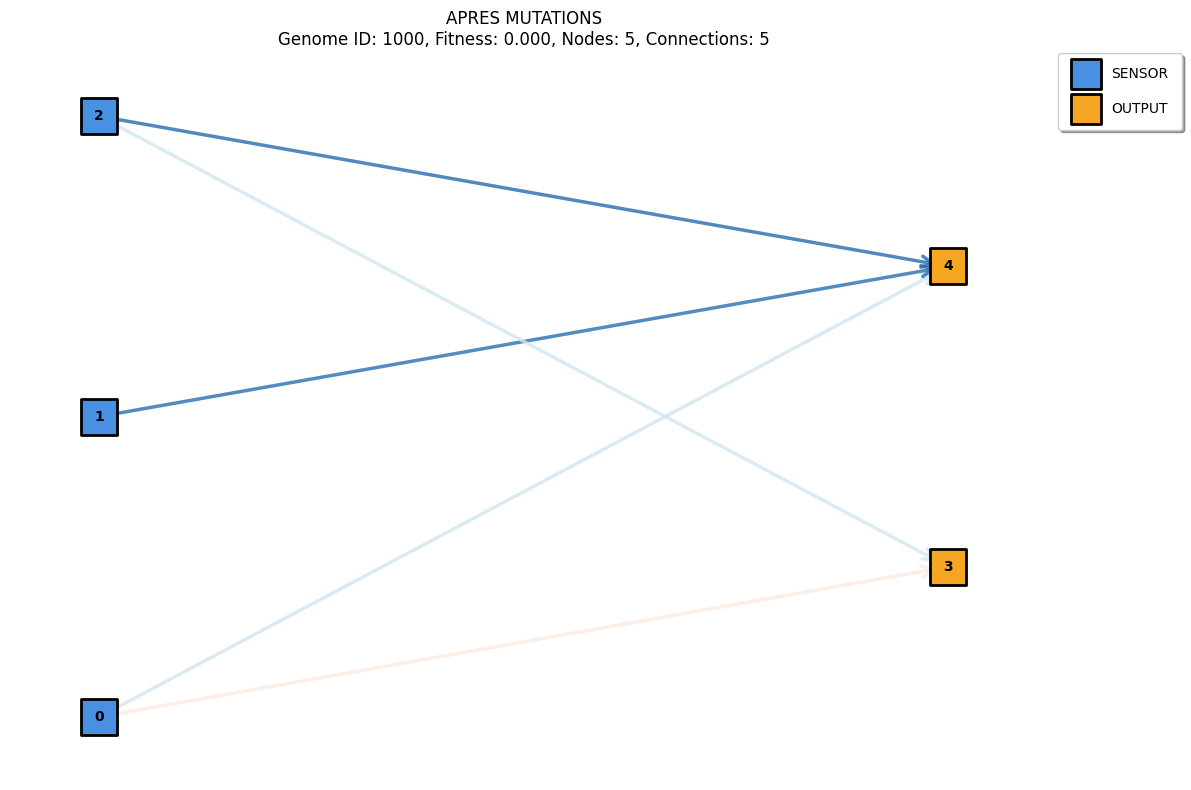

In [14]:
# Créer un génome simple NON fully connected
test_add_conn_genome = create_initial_genome(1000, num_inputs=3, num_outputs=2, fully_connected=False)
visualize_genome(test_add_conn_genome,title='AVANT MUTATIONS')
print("=" * 70)
print("TEST ADD_CONNECTION")
print("=" * 70)

print("\nAVANT mutation:")
print(test_add_conn_genome)
print(f"Connexions: {len(test_add_conn_genome.connections)}")
if test_add_conn_genome.connections:
    print("Liste des connexions:")
    for conn in test_add_conn_genome.connections:
        print(f"  {conn}")
else:
    print("Aucune connexion initiale")

print(f"\nNuméro d'innovation avant: {InnovationTracker.get_current()}")

# Ajouter plusieurs connexions
print("\n" + "-" * 70)
print("Ajout de 5 connexions...")
print("-" * 70)

for i in range(5):
    success = test_add_conn_genome.add_connection_mutation()
    if success:
        new_conn = test_add_conn_genome.connections[-1]
        print(f"\n✓ Connexion #{i+1} ajoutée:")
        print(f"  {new_conn}")
    else:
        print(f"\n✗ Échec #{i+1}: Aucune connexion possible")

print("\n" + "=" * 70)
print("APRÈS mutations:")
print(test_add_conn_genome)
print(f"\nConnexions totales: {len(test_add_conn_genome.connections)}")
print(f"Numéro d'innovation après: {InnovationTracker.get_current()}")
print("=" * 70)

visualize_genome(test_add_conn_genome,title='APRES MUTATIONS')

## 15. Test ADD_NODE - Ajouter un noeud

TEST ADD_NODE

AVANT mutation:
╔═══════════════════════════════════════════════╗
║ Genome ID: 2000                               ║
║ Fitness:   0.000000                           ║
╠═══════════════════════════════════════════════╣
║ STRUCTURE                                     ║
║   Inputs:  2                                  ║
║   Hidden:  0                                  ║
║   Outputs: 1                                  ║
║   Total:   3                                  ║
╠═══════════════════════════════════════════════╣
║ CONNECTIONS                                   ║
║   Active:   2                                 ║
║   Disabled: 0                                 ║
║   Total:    2                                 ║
╚═══════════════════════════════════════════════╝

Noeuds: 3
  [0] Node(type=sensor, activation=linear, bias=0.00, layer=0.00, value=0.00)
  [1] Node(type=sensor, activation=linear, bias=0.00, layer=0.00, value=0.00)
  [2] Node(type=output, activation=sigmoid, bias=0.0

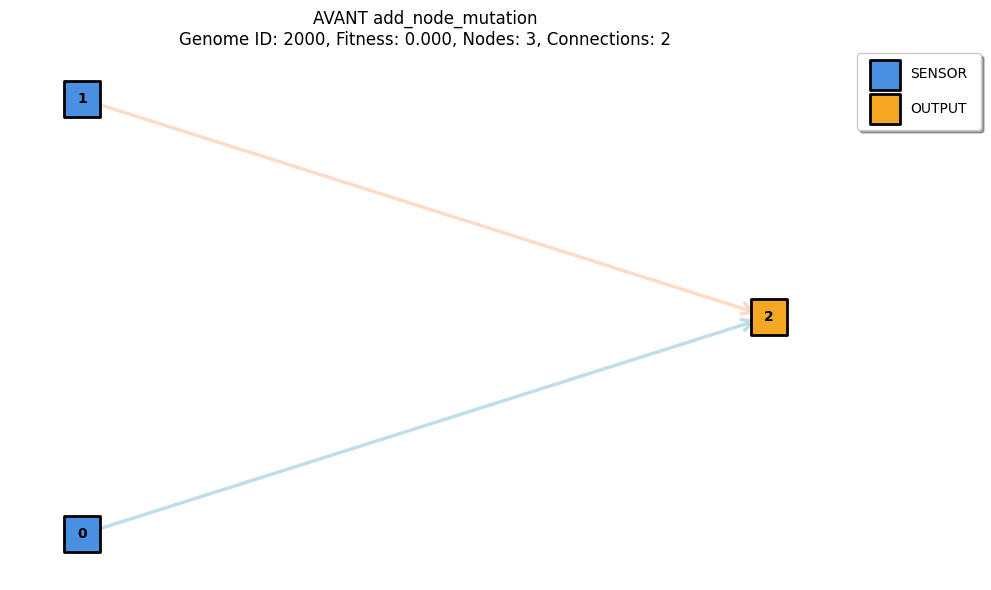


----------------------------------------------------------------------
Application de add_node_mutation()...
----------------------------------------------------------------------
✓ Noeud ajouté avec succès!

APRÈS mutation:
╔═══════════════════════════════════════════════╗
║ Genome ID: 2000                               ║
║ Fitness:   0.000000                           ║
╠═══════════════════════════════════════════════╣
║ STRUCTURE                                     ║
║   Inputs:  2                                  ║
║   Hidden:  1                                  ║
║   Outputs: 1                                  ║
║   Total:   4                                  ║
╠═══════════════════════════════════════════════╣
║ CONNECTIONS                                   ║
║   Active:   3                                 ║
║   Disabled: 1                                 ║
║   Total:    4                                 ║
╚═══════════════════════════════════════════════╝

Noeuds: 4
  [0] Node(ty

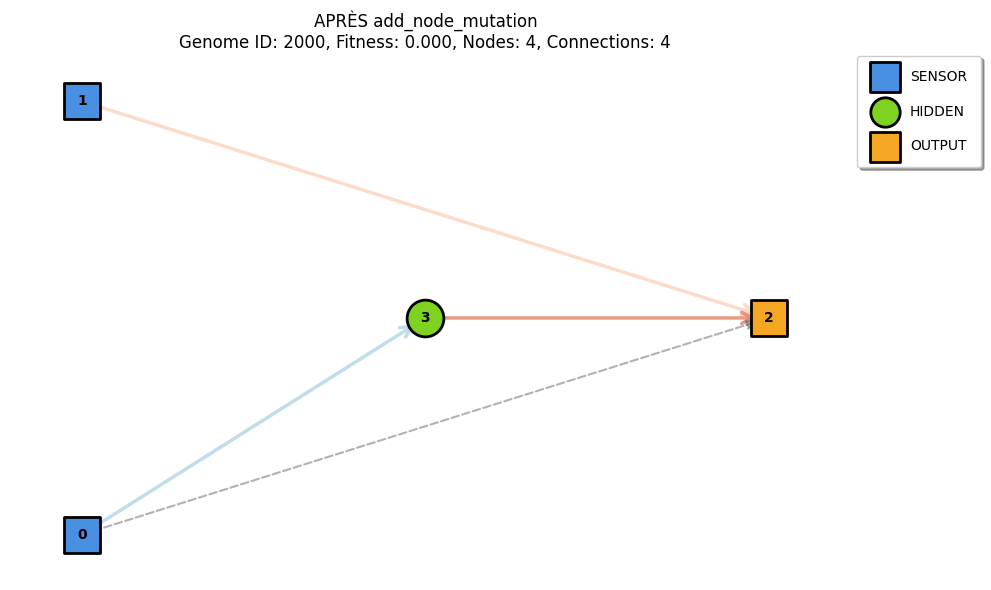

In [15]:
# Créer un génome avec quelques connexions
test_add_node_genome = create_initial_genome(2000, num_inputs=2, num_outputs=1, fully_connected=True)
print("=" * 70)
print("TEST ADD_NODE")
print("=" * 70)

print("\nAVANT mutation:")
print(test_add_node_genome)
print(f"\nNoeuds: {len(test_add_node_genome.nodes)}")
for i, node in enumerate(test_add_node_genome.nodes):
    print(f"  [{i}] {node}")
print(f"\nConnexions: {len(test_add_node_genome.connections)}")
for conn in test_add_node_genome.connections:
    print(f"  {conn}")

# Visualiser AVANT
print("\n" + "=" * 70)
print("VISUALISATION AVANT")
print("=" * 70)
visualize_genome(test_add_node_genome, title="AVANT add_node_mutation", figsize=(10, 6))

# Ajouter un noeud
print("\n" + "-" * 70)
print("Application de add_node_mutation()...")
print("-" * 70)

success = test_add_node_genome.add_node_mutation()

if success:
    print("✓ Noeud ajouté avec succès!")
else:
    print("✗ Échec de l'ajout de noeud")

print("\n" + "=" * 70)
print("APRÈS mutation:")
print(test_add_node_genome)
print(f"\nNoeuds: {len(test_add_node_genome.nodes)}")
for i, node in enumerate(test_add_node_genome.nodes):
    print(f"  [{i}] {node}")
print(f"\nConnexions: {len(test_add_node_genome.connections)}")
for conn in test_add_node_genome.connections:
    state = "✓ ACTIVE" if conn.enabled else "✗ DISABLED"
    print(f"  {conn} - {state}")

print(f"\nNuméro d'innovation: {InnovationTracker.get_current()}")
print("=" * 70)
visualize_genome(test_add_node_genome, title="APRÈS add_node_mutation", figsize=(10, 6))


TEST ADD_NODE

AVANT mutation:
╔═══════════════════════════════════════════════╗
║ Genome ID: 2000                               ║
║ Fitness:   0.000000                           ║
╠═══════════════════════════════════════════════╣
║ STRUCTURE                                     ║
║   Inputs:  2                                  ║
║   Hidden:  0                                  ║
║   Outputs: 1                                  ║
║   Total:   3                                  ║
╠═══════════════════════════════════════════════╣
║ CONNECTIONS                                   ║
║   Active:   2                                 ║
║   Disabled: 0                                 ║
║   Total:    2                                 ║
╚═══════════════════════════════════════════════╝

Noeuds: 3
  [0] Node(type=sensor, activation=linear, bias=0.00, layer=0.00, value=0.00)
  [1] Node(type=sensor, activation=linear, bias=0.00, layer=0.00, value=0.00)
  [2] Node(type=output, activation=sigmoid, bias=0.0

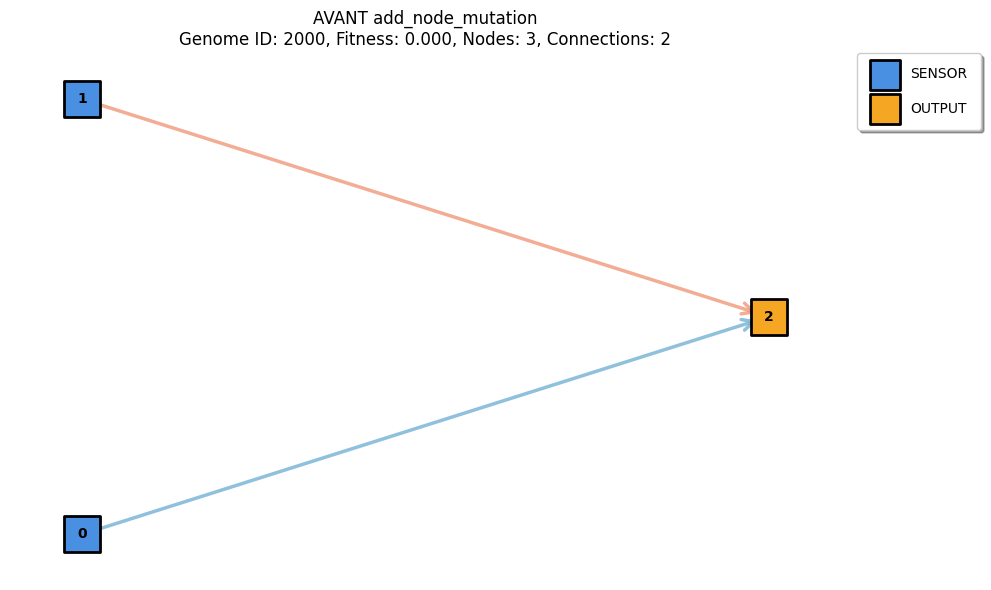


----------------------------------------------------------------------
Application de add_node_mutation()...
----------------------------------------------------------------------

APRÈS mutation:
╔═══════════════════════════════════════════════╗
║ Genome ID: 2000                               ║
║ Fitness:   0.000000                           ║
╠═══════════════════════════════════════════════╣
║ STRUCTURE                                     ║
║   Inputs:  2                                  ║
║   Hidden:  10                                 ║
║   Outputs: 1                                  ║
║   Total:   13                                 ║
╠═══════════════════════════════════════════════╣
║ CONNECTIONS                                   ║
║   Active:   14                                ║
║   Disabled: 8                                 ║
║   Total:    22                                ║
╚═══════════════════════════════════════════════╝

Noeuds: 13
  [0] Node(type=sensor, activation=linea

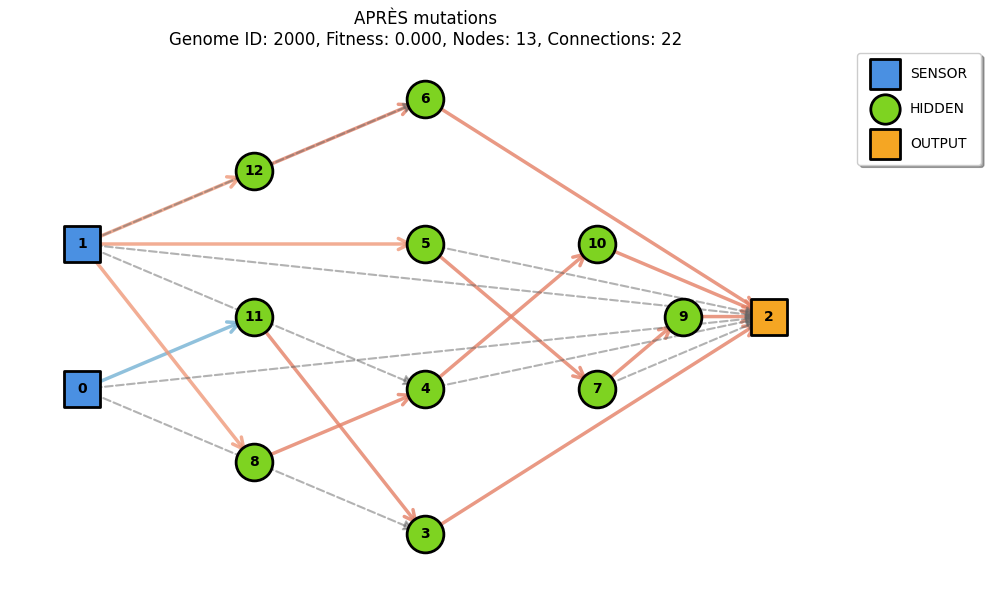

In [16]:
# Créer un génome avec quelques connexions
test_add_node_genome = create_initial_genome(2000, num_inputs=2, num_outputs=1, fully_connected=True)
print("=" * 70)
print("TEST ADD_NODE")
print("=" * 70)

print("\nAVANT mutation:")
print(test_add_node_genome)
print(f"\nNoeuds: {len(test_add_node_genome.nodes)}")
for i, node in enumerate(test_add_node_genome.nodes):
    print(f"  [{i}] {node}")
print(f"\nConnexions: {len(test_add_node_genome.connections)}")
for conn in test_add_node_genome.connections:
    print(f"  {conn}")

# Visualiser AVANT
print("\n" + "=" * 70)
print("VISUALISATION AVANT")
print("=" * 70)
visualize_genome(test_add_node_genome, title="AVANT add_node_mutation", figsize=(10, 6))

# Ajouter un noeud
print("\n" + "-" * 70)
print("Application de add_node_mutation()...")
print("-" * 70)

for i in range(10):
    test_add_node_genome.add_node_mutation()


print("\n" + "=" * 70)
print("APRÈS mutation:")
print(test_add_node_genome)
print(f"\nNoeuds: {len(test_add_node_genome.nodes)}")
for i, node in enumerate(test_add_node_genome.nodes):
    print(f"  [{i}] {node}")
print(f"\nConnexions: {len(test_add_node_genome.connections)}")
for conn in test_add_node_genome.connections:
    state = "✓ ACTIVE" if conn.enabled else "✗ DISABLED"
    print(f"  {conn} - {state}")

print(f"\nNuméro d'innovation: {InnovationTracker.get_current()}")
print("=" * 70)
visualize_genome(test_add_node_genome, title="APRÈS mutations", figsize=(10, 6))


## Test Simple du Crossover

Mutation des parents...
Parent 1: 7 nœuds, 16 connexions, fitness=0.8
Parent 2: 8 nœuds, 15 connexions, fitness=0.6
Offspring: 7 nœuds, 16 connexions


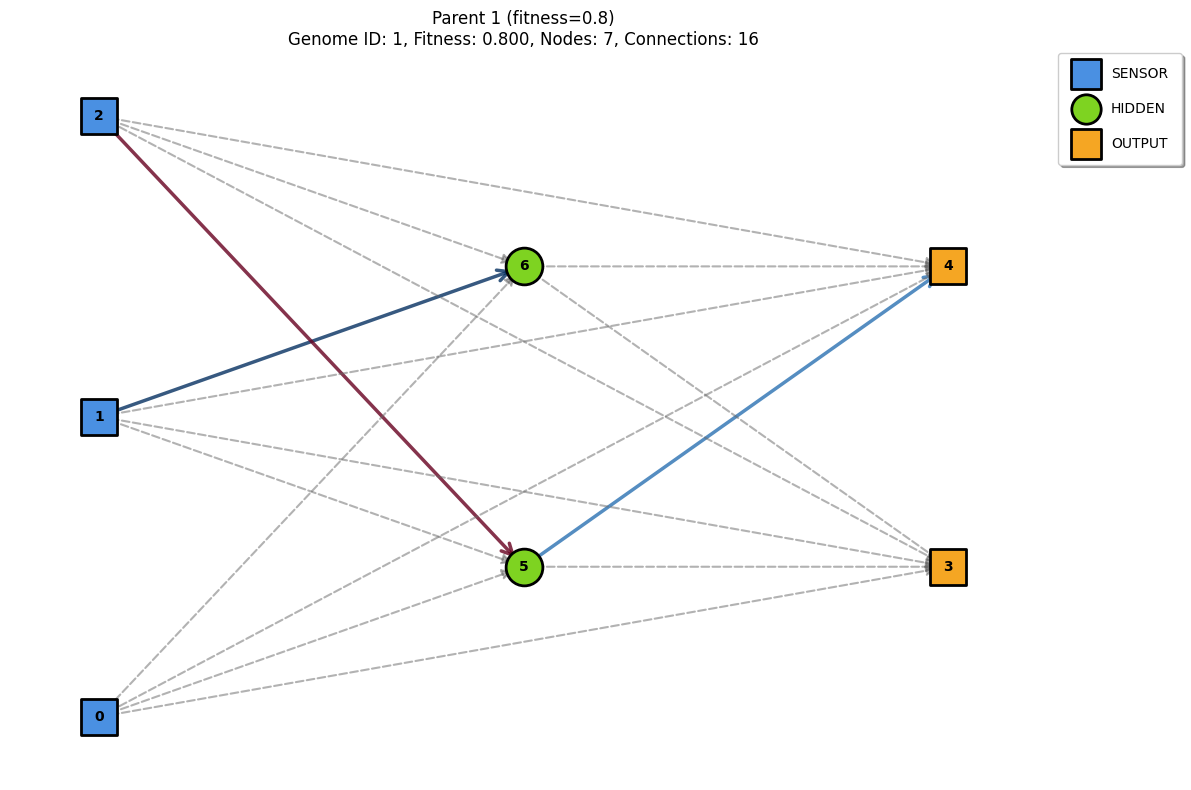

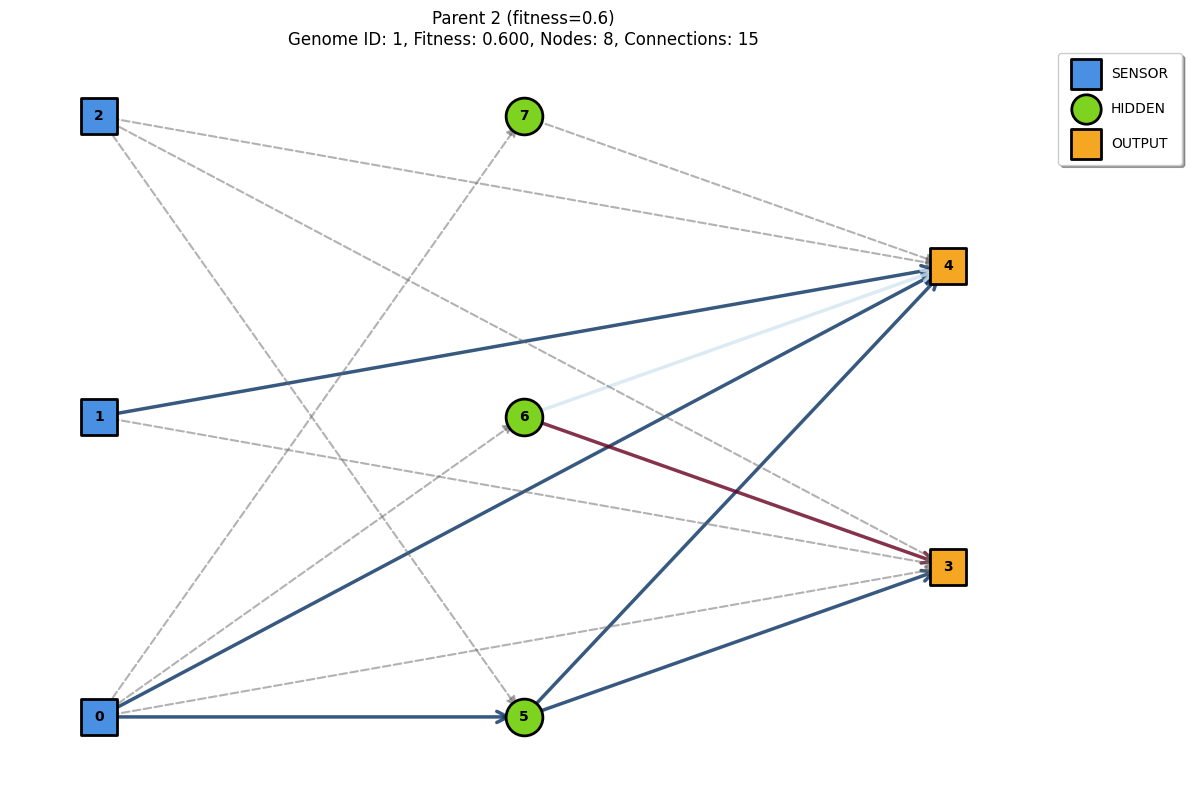

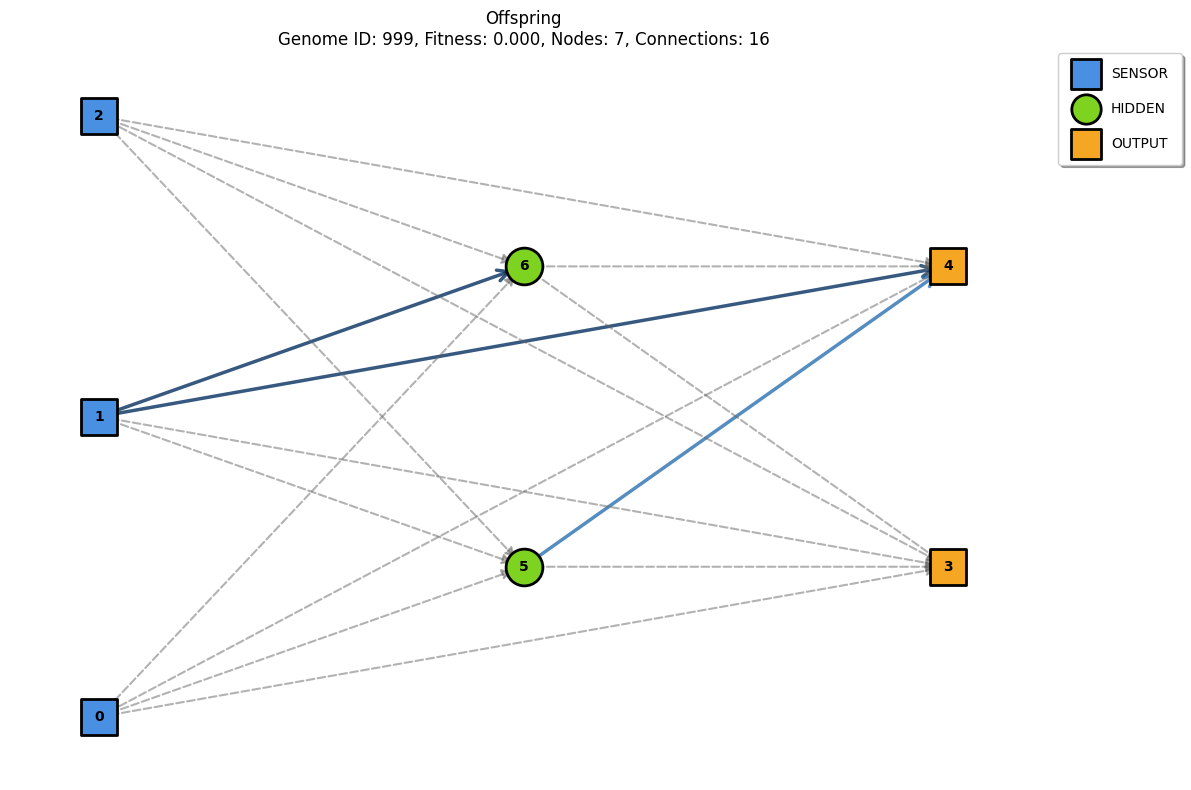

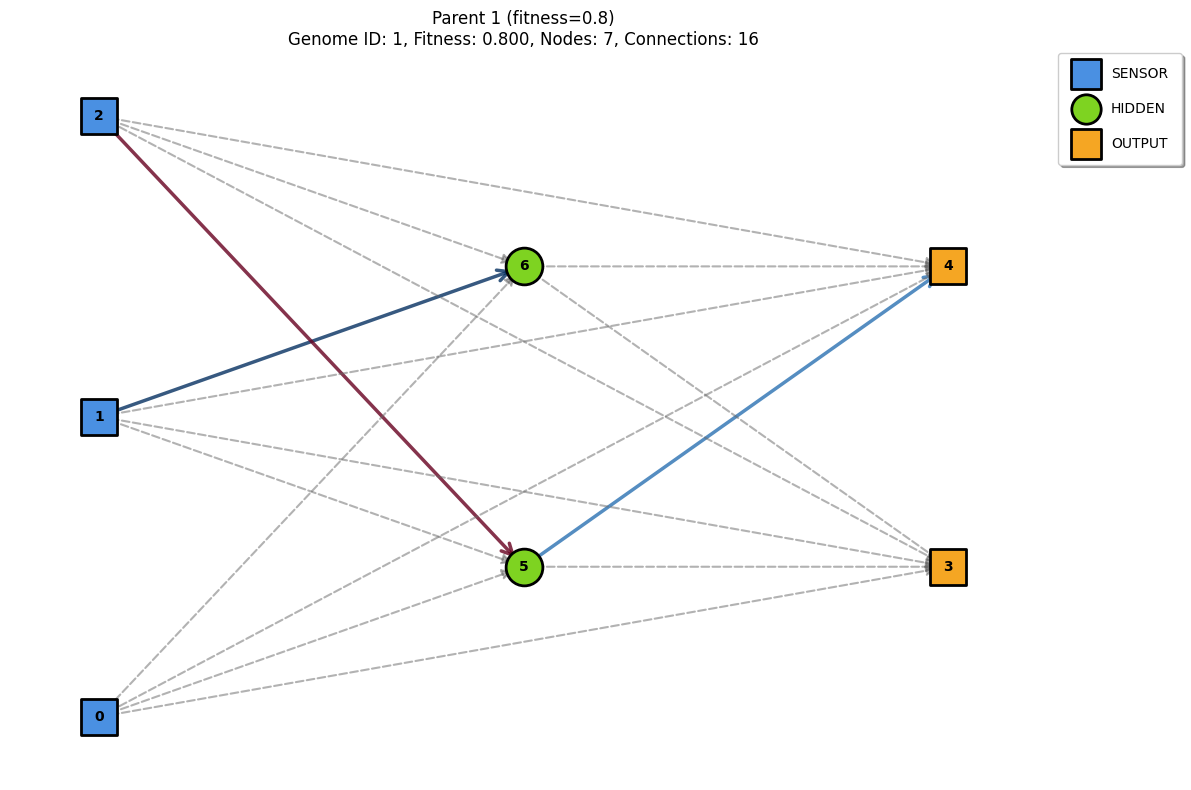

<Figure size 640x480 with 0 Axes>

In [17]:
# Réinitialiser
InnovationTracker.reset()

# Créer un genome
p = create_initial_genome(1, num_inputs=3, num_outputs=2, fully_connected=True)

mut_config = MutationConfig()
# Appliquer 50 mutations commune aux deux parents
print("Mutation des parents...")
for _ in range(50):
    p.mutate(mut_config)
    
p1 = p.copy()
p2 = p.copy()

for _ in range(100):
    p1.mutate(mut_config)
    p2.mutate(mut_config)

# Assigner des fitness
p1.fitness = 0.8
p2.fitness = 0.6

print(f"Parent 1: {len(p1.nodes)} nœuds, {len(p1.connections)} connexions, fitness={p1.fitness}")
print(f"Parent 2: {len(p2.nodes)} nœuds, {len(p2.connections)} connexions, fitness={p2.fitness}")

# Faire le crossover
child = crossover(p1, p2, offspring_id=999)
print(f"Offspring: {len(child.nodes)} nœuds, {len(child.connections)} connexions")

visualize_genome(p1, title=f"Parent 1 (fitness={p1.fitness})")
visualize_genome(p2, title=f"Parent 2 (fitness={p2.fitness})")
visualize_genome(child, title="Offspring")
visualize_genome(p1, title=f"Parent 1 (fitness={p1.fitness})")

plt.tight_layout()
plt.show()